In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

SEED = 42
TARGET = 'stroke'

In [61]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print('Ukuran data:', df.shape)
df.sample(5)

Ukuran data: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2115,8345,Female,49.0,0,0,Yes,Private,Rural,114.76,24.7,never smoked,0
2916,60145,Female,38.0,0,0,Yes,Private,Urban,77.35,27.7,never smoked,0
314,11120,Female,78.0,1,0,Yes,Private,Urban,218.46,34.3,never smoked,0
212,31179,Male,63.0,0,0,Yes,Private,Urban,208.65,30.7,never smoked,1
2537,19769,Female,67.0,0,0,Yes,Self-employed,Rural,80.18,22.9,formerly smoked,0


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [63]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [64]:
print(df[TARGET].value_counts())

stroke
0    4861
1     249
Name: count, dtype: int64


# Modul B - Klasifikasi
## B.1 Split data strastified 70 / 15 / 15

**Strastified** dikarenakan data target memiliki perbedaan nilai yang besar diantara kategori 4861 sehat vs 249 stroke jadi perlu di strastified agar pengacakan adil

**70 / 15 / 15** agar ia tetap dapat data training yang memiliki kuantitas yang mumpuni baik bagi Training, Validate, dan Testing

In [65]:
def strastified_split(y, fracs=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.default_rng(seed)
    parts = [[], [], []]
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        n_tr = int(round(fracs[0] * len(idx)))
        n_va = int(round(fracs[1] * len(idx)))
        parts[0].append(idx[:n_tr])
        parts[1].append(idx[n_tr:n_tr + n_va])
        parts[2].append(idx[n_tr + n_va:])
    return  [rng.permutation(np.concatenate(p)) for p in parts]

idx_tr, idx_va, idx_te = strastified_split(df[TARGET].values)
train_df, val_df, test_df = df.iloc[idx_tr].copy(), df.iloc[idx_va].copy(), df.iloc[idx_te].copy()

bagian = {'semua': df, 'latih (70%)': train_df, 'validasi (15%)': val_df, 'uji (15%)': test_df}
print(pd.DataFrame({'jumlah': [len(d) for d in bagian.values()],
                    TARGET: [d[TARGET].sum() for d in bagian.values()],
                    '% stroke': [round(d[TARGET].mean() * 100, 2) for d in bagian.values()]}, index=bagian.keys()))

                jumlah  stroke  % stroke
semua             5110     249      4.87
latih (70%)       3577     174      4.86
validasi (15%)     766      37      4.83
uji (15%)          767      38      4.95


In [66]:
print(df['smoking_status'].value_counts())
print(df['work_type'].value_counts())

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64


## B.2 Preprocessing (fit di train, transform di semua split agar tidak ada data leakage)

### Langkah yang akan kita lakukan:
1. **Imputasi BMI**, diinput dengan median BMI **PER** kelompok usia
2. **Encoding biner** `gender` -> `is_male`, `ever_married` -> 1/0, `Residence_type` -> `is_urban`
3. **One-Hot encoding** untuk `work_type` dan `smoking_status` dengan **MEMBUANG** kategori pertama/dijadikan baseline untuk mencegah yang namanya dummy variable trap. Selain itu penggunaan one-hot encoding dan bukannnya label encoding dikarenakan label encoding memakasa ururtan dan jarak yang sama (Misal di column `smoking_status` Unkown < never < formely < smokes) dan juga datanya tidak akurat/kasar (1544 orang status smokingnya unknown, dan juga w2925 orang tidak memberitahu work_type mereka (private))
4. **Normalisasi dengan z-score**, dikarenakan gradient descent memakai **satu learning rate untuk semua bobot**. Jika usia (0-82) dan glukosa (55-272) tidak disakalakan, gradiennya timpang dan training lambat atau zig-zag. Setelah z-score, besar koefisien juga bisa dibandingkan antar fitur. Z-score dipilih daripada min-max karena glukosa punya outlier yang dipertahankan; min-max akan "menekan" mayoritas data ke rentang sempit.

In [67]:
AGE_BINS = [0, 13, 18, 30, 45, 60, 200]
AGE_LABELS = ['0-12', '13-17','18-29', '30-44', '45-59', '60+']

class Preprocessor:
    """Semua parameter dipelajari dari data training jadi tidak ada data leakage"""
    NUM = ['age', 'avg_glucose_level', 'bmi']
    ONESHOT = {'work_type': 'Private', 'smoking_status': 'never smoked'}  # Nilai diambil dari data yang jumlahnya paling banyak

    def fit(self, d):
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False)
        self.bmi_median = d.groupby(grp, observed=False)['bmi'].median().to_dict()
        d = self._impute(d)
        self.mean = d[self.NUM].mean().to_dict()
        self.std = d[self.NUM].std().to_dict()
        self.categories = {c: sorted(v for v in d[c].unique() if v != base)
                            for c, base in self.ONESHOT.items()}
        return self

    def _impute(self, d):
        d = d.copy()
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False).astype(str)
        d['bmi'] = d['bmi'].fillna(grp.map(self.bmi_median))
        return d

    def transform(self, d):
        d = self._impute(d)
        X = pd.DataFrame(index=d.index)
        for c in self.NUM:
            X[c] = (d[c] - self.mean[c]) / self.std[c]
        X['hypertension'] = d['hypertension']
        X['heart_disease'] = d['heart_disease']
        X['is_male'] = (d['gender'] == 'Male').astype(int)
        X['ever_married'] = (d['ever_married'] == 'Yes').astype(int)
        X['is_urban'] = (d['Residence_type'] == 'Urban').astype(int)
        for c, cats in self.categories.items():
            for v in cats:
                X[f'{c}={v}'] = (d[c] == v).astype(int)
        return X.astype(float)

prep = Preprocessor().fit(train_df)
X_train_df, X_val_df, X_test_df = prep.transform(train_df), prep.transform(val_df), prep.transform(test_df)
y_train, y_val, y_test = (d['stroke'].values.astype(float) for d in (train_df, val_df, test_df))
FEATURES_ALL = list(X_train_df.columns)

print('Median BMI per kelompok usia (dari train):', {k: round(v, 1) for k, v in prep.bmi_median.items()})
print('Sisa NaN setelah transform:', int(X_train_df.isna().sum().sum() + X_val_df.isna().sum().sum() + X_test_df.isna().sum().sum()))
print('Jumlah fitur:', len(FEATURES_ALL))
X_train_df.head()

Median BMI per kelompok usia (dari train): {'0-12': 18.6, '13-17': 23.8, '18-29': 26.5, '30-44': 29.8, '45-59': 30.3, '60+': 29.4}
Sisa NaN setelah transform: 0
Jumlah fitur: 15


,age,avg_glucose_level,bmi,hypertension,heart_disease,is_male,ever_married,is_urban,work_type=Govt_job,work_type=Never_worked,work_type=Self-employed,work_type=children,smoking_status=Unknown,smoking_status=formerly smoked,smoking_status=smokes
774,-0.539885,-1.124779,0.474674,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3281,-1.691943,-0.712365,-1.535019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1574,1.365442,-0.880426,0.724244,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2306,-0.406955,-0.418478,1.249654,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2691,0.080454,-0.048521,0.474674,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [68]:
print('Cek normalisasi di train (harus mean ~0, std ~1):')
print(X_train_df[Preprocessor.NUM].agg(['mean', 'std']).round(3))

Cek normalisasi di train (harus mean ~0, std ~1):
      age  avg_glucose_level  bmi
mean -0.0                0.0  0.0
std   1.0                1.0  1.0


## B.3 Logistic Regression

In [69]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=2000, class_weight=None):
        self.lr, self.epochs, self.class_weight = lr, epochs, class_weight

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _sample_weight(self, y):
        if self.class_weight is None:
            return np.ones_like(y)
        return np.where(y == 1, self.class_weight[1], self.class_weight[0])

    def loss(self, X, y, w=None, b=None):
        w = self.w if w is None else w
        b = self.b if b is None else b
        p = np.clip(self.sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
        s = self._sample_weight(y)
        return -np.sum(s * (y * np.log(p) + (1 - y) * np.log(1 - p))) / s.sum()

    def gradient(self, X, y, w, b):
        s = self._sample_weight(y)
        err = s * (self.sigmoid(X @ w + b) - y)
        return X.T @ err / s.sum(), err.sum() / s.sum()

    def fit(self, X, y, X_val=None, y_val=None):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.history = {'train': [], 'val': []}
        for _ in range(self.epochs):
            self.history['train'].append(self.loss(X, y))
            if X_val is not None:
                self.history['val'].append(self.loss(X_val, y_val))
            dw, db = self.gradient(X, y, self.w, self.b)
            self.w -= self.lr * dw
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## B.4 Membuktikan Training berjalan dengan benar

Ada tiga bukti yang akan kita gunakan:
1. Loss awal sesuai dengan teori (Rumus loss awal -ln(1/n))
2. Gradien analitik sama dengan gradien numerik
3. Loss turun dan stabil

In [70]:
Xtr, Xva, Xte = X_train_df.values, X_val_df.values, X_test_df.values

# Bukti 1: dengan w=0 dan b=0, semua prediksi 0.5 -> loss harus ln(2)
m = LogisticRegression()
print(f'Loss awal = {m.loss(Xtr, y_train, np.zeros(Xtr.shape[1]), 0.0):.4f} | ln 2 = {np.log(2):.4f}')

# Bukti 2: gradoemt check dengan beda yang sangat kecil
rng = np.random.default_rng(SEED)
w0, b0, eps = rng.normal(0, 0.1, Xtr.shape[1]), 0.1, 1e-5
dw, _ = m.gradient(Xtr, y_train, w0, b0)
num = np.array([(m.loss(Xtr, y_train, w0 + eps * e, b0) - m.loss(Xtr, y_train, w0 - eps * e, b0)) / (2 * eps)
                for e in np.eye(len(w0))])
print(f'Selisih maksimum gradien analitik vs numerik {np.max(np.abs(dw - num)):.2e} (Harus sangat kecil)')

Loss awal = 0.6931 | ln 2 = 0.6931
Selisih maksimum gradien analitik vs numerik 7.59e-12 (Harus sangat kecil)


Loss train: 0.6931 -> 0.1583
Loss val  : 0.6931 -> 0.1571


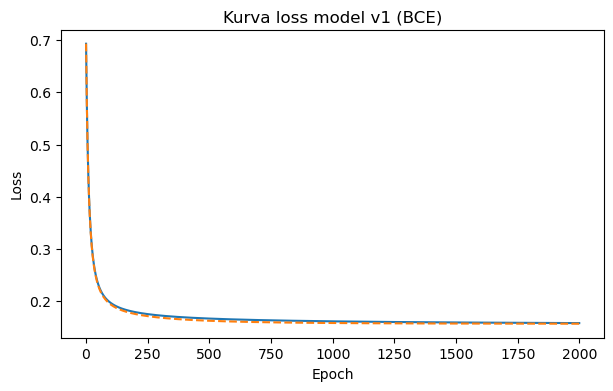

In [71]:
# Bukti 3 loss turun dan stabil

model_v1 = LogisticRegression(lr=0.1, epochs=2000).fit(Xtr, y_train, Xva, y_val)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(model_v1.history['train'], label='train')
ax.plot(model_v1.history['val'], label='validasi', ls='--')
ax.set_title('Kurva loss model v1 (BCE)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
print(f"Loss train: {model_v1.history['train'][0]:.4f} -> {model_v1.history['train'][-1]:.4f}")
print(f"Loss val  : {model_v1.history['val'][0]:.4f} -> {model_v1.history['val'][-1]:.4f}")

# MODUL C - Evaluasi Model
## C.1 Confusion Matrix dan metrik tanpa library

1. **Recall** = TP / (TP + FN): Dari semua pasien stroke berapa yang tertangkap
2. **Precision** = TP / (TP + FP): dari yang diberi alarm berapa yang benar benar stroke
3. **F1** = rata-rata precision dan recall
4. **AUC (ROC)**: Peliang model memberi skor lebih tinggi ke pasien stroke daripada pasien sehat

**Pilihan penggunaan metrik:** ini alat **skrining**. FN (pasien berisiko dinyatakan aman) jauh lebih penting daripada FP (pasien sehat diminta cek lanjutan). Karena itu **recall menjadi metrik utama**, dengan precision dan F1 sebagai penyeimbang agar model tidak asal memberi alarm ke semua orang. AUC dipakai untuk membandingkan model sebelum memilih threshold.

In [72]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def safe_div(a, b):
    return a / b if  b else 0.0

def roc_auc(y_true, score):
    """AUC via statistik Mann-Whitney: rata-rata peringkat skor kelas positif."""
    ranks = pd.Series(score).rank().values          # rank rata-rata untuk nilai yang sama
    pos = np.asarray(y_true) == 1
    n_pos, n_neg = pos.sum(), (~pos).sum()
    return (ranks[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def evaluate(y_true, proba, threshold=0.5):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    prec, rec = safe_div(tp, tp + fp), safe_div(tp, tp + fn)
    return {'threshold': threshold, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
            'accuracy': (tp + tn) / (tp + fn + fp + tn), 'precision': prec, 'recall': rec,
            'specificity': safe_div(tn, tn + fp), 'f1': safe_div(2 * prec * rec, prec + rec),
            'auc': float(roc_auc(y_true, proba))}

def plot_cm(ax, y_true, proba, threshold, title):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    cm = np.array([[tp, fn], [fp, tn]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Prediksi stroke', 'Prediksi tidak'],
                yticklabels=['Aktual stroke', 'Aktual tidak'], annot_kws={'size': 13})
    ax.set_title(title)




## C.2 Evaluasi model v1 (baseline) di data validasi

In [73]:
p_val_v1 = model_v1.predict_proba(Xva)
res_v1 = evaluate(y_val, p_val_v1, 0.5)
baseline_acc = 1 - y_val.mean()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v1.items()})

print(f'Hasil evaluasi model -> akurasi {baseline_acc:.3f}, recall 0')

{'threshold': 0.5, 'TP': 0, 'FN': 37, 'FP': 0, 'TN': 729, 'accuracy': 0.952, 'precision': 0.0, 'recall': 0.0, 'specificity': 1.0, 'f1': 0.0, 'auc': 0.84}
Hasil evaluasi model -> akurasi 0.952, recall 0


**Insight**: akurasi v1 terlihat bagus (~95%), tetapi **recall 0** yang berarti tidak ada satu pun pasien stroke yang terdeteksi. Hal ini menunjukkan bahwa Model v1 menebak "tidak stroke" untuk semua orang. AUC-nya cukup baik (`0.8), jadi seharusnya model bisa mengurutkan resiko stroke hanya saja probalitasnya tidak pernah melewari 0.5 threshold yang kita pasang

Dua penyebabnya kemungkinan besar:
1. Loss didominasi kelas mayoritas -> diperbaiki degan class weight
2. Threshold 0.5 tidak cocok untuk kasus ini -> Kita akan tuning threshold

## C.3 Perbaikan Class Weight

In [ ]:
n, n_pos = len(y_train), y_train.sum()
CLASS_WEIGHT = {0: float(n / (2 * (n - n_pos))), 1: float(n / (2 * n_pos))}
print('Class weight:', {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

model_v2 = LogisticRegression(lr=0.1, epochs=2000, class_weight=CLASS_WEIGHT).fit(Xtr, y_train, Xva, y_val)
res_v2 = evaluate(y_val, model_v2.predict_proba(Xva), 0.5)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v2.items()})